# 02 — Preprocessing Pipeline Demo

Demonstrates the image preprocessing pipeline:
- Fundus auto-crop
- CLAHE enhancement
- Ben Graham colour normalisation
- Albumentations augmentation preview

In [8]:
import os, sys, importlib, shutil

# --- CONFIGURE DATA SOURCE ---
# "kaggle" = download from Kaggle (~1-3 min, recommended for Colab)
# "drive"  = copy from Google Drive (~15-30 min, fallback)
# "local"  = data already at expected path (no copy needed)
DATA_SOURCE = "kaggle"

IS_COLAB = 'google.colab' in str(get_ipython()) if 'get_ipython' in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/diabetic_retinopathy'
    %pip install -q timm albumentations

    LOCAL_DATA = '/content/dataset'
    if not os.path.isdir(os.path.join(LOCAL_DATA, 'resized_train_cropped')):
        if DATA_SOURCE == "kaggle":
            print('Upload your kaggle.json when prompted...')
            from google.colab import files
            uploaded = files.upload()  # user uploads kaggle.json
            os.makedirs('/root/.kaggle', exist_ok=True)
            shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')
            os.chmod('/root/.kaggle/kaggle.json', 0o600)
            !kaggle datasets download -d tanlikesmath/diabetic-retinopathy-resized -p /content/ -q
            os.makedirs(LOCAL_DATA, exist_ok=True)
            import zipfile
            with zipfile.ZipFile('/content/diabetic-retinopathy-resized.zip', 'r') as z:
                z.extractall(LOCAL_DATA)
            os.remove('/content/diabetic-retinopathy-resized.zip')
            print('Kaggle download complete!')
        elif DATA_SOURCE == "drive":
            print('Copying dataset from Drive to local SSD (15-30 min)...')
            shutil.copytree(
                os.path.join(PROJECT_ROOT, 'dataset'), LOCAL_DATA,
                dirs_exist_ok=True,
            )
            print('Drive copy complete!')
    else:
        print('Dataset already on local SSD.')
else:
    PROJECT_ROOT = os.path.abspath('..')

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config

print(f'Images dir: {config.IMAGES_DIR}')
print(f'  exists: {os.path.isdir(config.IMAGES_DIR)}')
print(f'Outputs dir: {config.OUTPUTS_DIR}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset already on local SSD.
Images dir: /content/dataset/resized_train_cropped/resized_train_cropped
  exists: True
Outputs dir: /content/drive/MyDrive/diabetic_retinopathy/outputs


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from src import config
from src.utils import seed_everything
from src.preprocessing import (
    crop_fundus, apply_clahe, ben_graham_preprocessing,
    apply_circular_mask, preprocess_image, load_and_preprocess,
)
from src.augmentations import get_train_transforms, get_valid_transforms

seed_everything()

## 1. Step-by-Step Preprocessing

In [10]:
def find_image(images_dir, image_id):
    """Try common extensions and return the file path, or None."""
    for ext in ('.jpeg', '.jpg', '.png', '.JPEG', '.JPG'):
        p = os.path.join(images_dir, image_id + ext)
        if os.path.isfile(p):
            return p
    return None

# Pick a sample image
df = pd.read_csv(config.LABELS_CSV)
cols_to_drop = [c for c in df.columns if c.startswith('Unnamed')]
df = df.drop(columns=cols_to_drop, errors='ignore')

# Choose one image from each class
sample_images = {}
for cls in range(config.NUM_CLASSES):
    row = df[df['level'] == cls].sample(1, random_state=config.SEED).iloc[0]
    img_path = find_image(config.IMAGES_DIR, row['image'])
    if img_path is None:
        print(f'WARNING: Class {cls} — image not found for {row["image"]}')
        continue
    sample_images[cls] = img_path
    print(f'Class {cls} ({config.CLASS_CODE[cls]}): {img_path}')

Class 0 (No_DR): /content/dataset/resized_train_cropped/resized_train_cropped/4095_right.jpeg
Class 1 (Mild): /content/dataset/resized_train_cropped/resized_train_cropped/7797_left.jpeg
Class 2 (Moderate): /content/dataset/resized_train_cropped/resized_train_cropped/3525_left.jpeg
Class 3 (Severe): /content/dataset/resized_train_cropped/resized_train_cropped/39521_right.jpeg
Class 4 (Proliferative_DR): /content/dataset/resized_train_cropped/resized_train_cropped/8462_left.jpeg


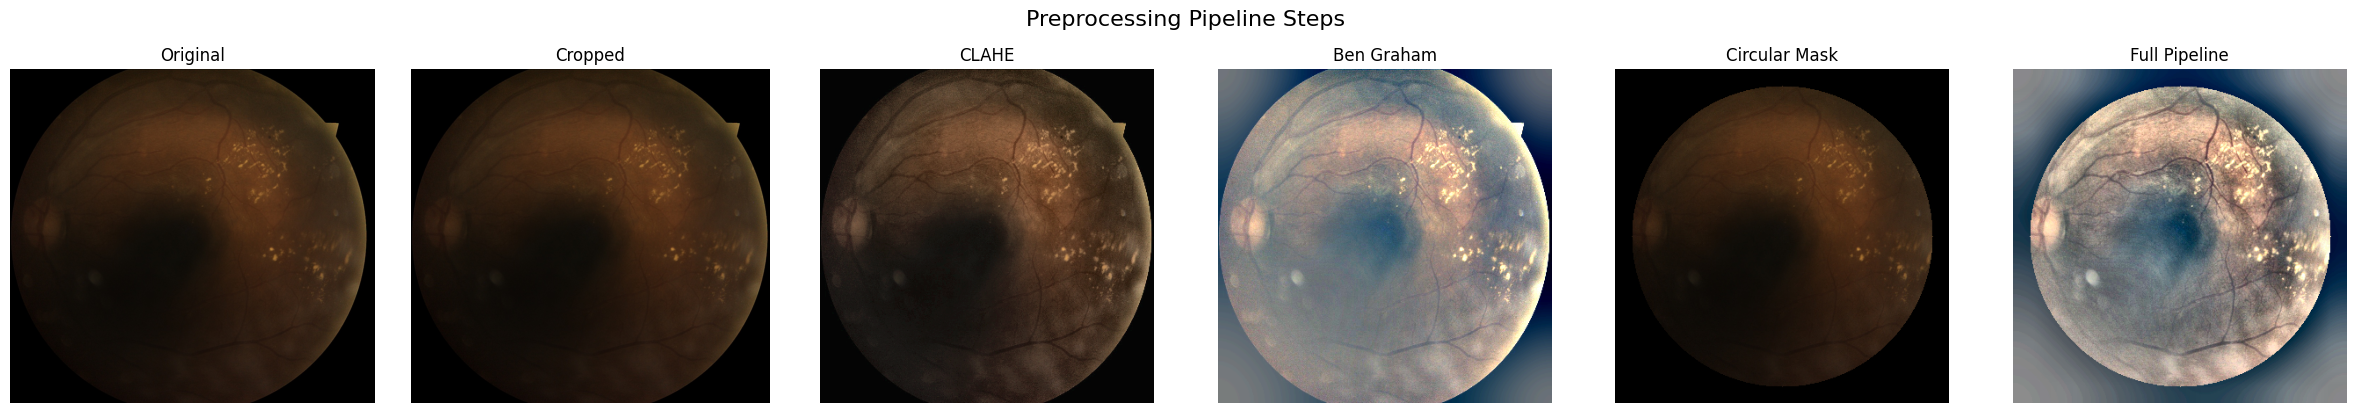

In [11]:
# Show step-by-step pipeline for one image
img_path = sample_images[2]  # Moderate DR
original = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)

steps = {
    'Original': original,
    'Cropped': crop_fundus(original.copy()),
    'CLAHE': apply_clahe(cv2.resize(crop_fundus(original.copy()), (config.IMG_SIZE, config.IMG_SIZE))),
    'Ben Graham': ben_graham_preprocessing(cv2.resize(crop_fundus(original.copy()), (config.IMG_SIZE, config.IMG_SIZE))),
    'Circular Mask': apply_circular_mask(cv2.resize(crop_fundus(original.copy()), (config.IMG_SIZE, config.IMG_SIZE))),
    'Full Pipeline': preprocess_image(original.copy()),
}

fig, axes = plt.subplots(1, len(steps), figsize=(4 * len(steps), 4))
fig.suptitle('Preprocessing Pipeline Steps', fontsize=16, y=1.02)

for ax, (name, img) in zip(axes, steps.items()):
    ax.imshow(img)
    ax.set_title(name, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, 'preprocessing_steps.png'), dpi=150, bbox_inches='tight')
plt.show()

## 2. Preprocessing Across All Classes

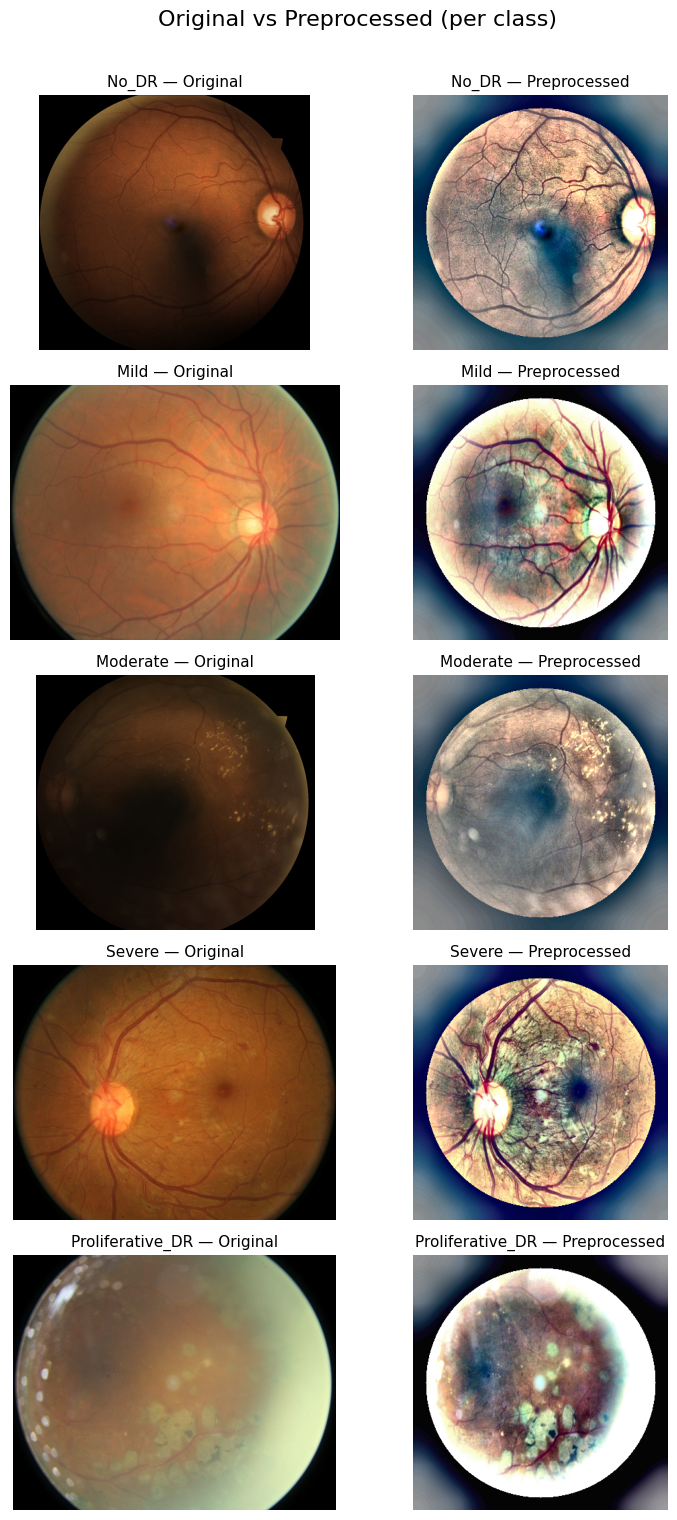

In [12]:
fig, axes = plt.subplots(config.NUM_CLASSES, 2, figsize=(8, 3 * config.NUM_CLASSES))
fig.suptitle('Original vs Preprocessed (per class)', fontsize=16, y=1.01)

for cls in range(config.NUM_CLASSES):
    img = cv2.cvtColor(cv2.imread(sample_images[cls]), cv2.COLOR_BGR2RGB)
    processed = preprocess_image(img.copy())

    axes[cls, 0].imshow(img)
    axes[cls, 0].set_title(f'{config.CLASS_CODE[cls]} — Original', fontsize=11)
    axes[cls, 0].axis('off')

    axes[cls, 1].imshow(processed)
    axes[cls, 1].set_title(f'{config.CLASS_CODE[cls]} — Preprocessed', fontsize=11)
    axes[cls, 1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, 'preprocessing_all_classes.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Augmentation Preview

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


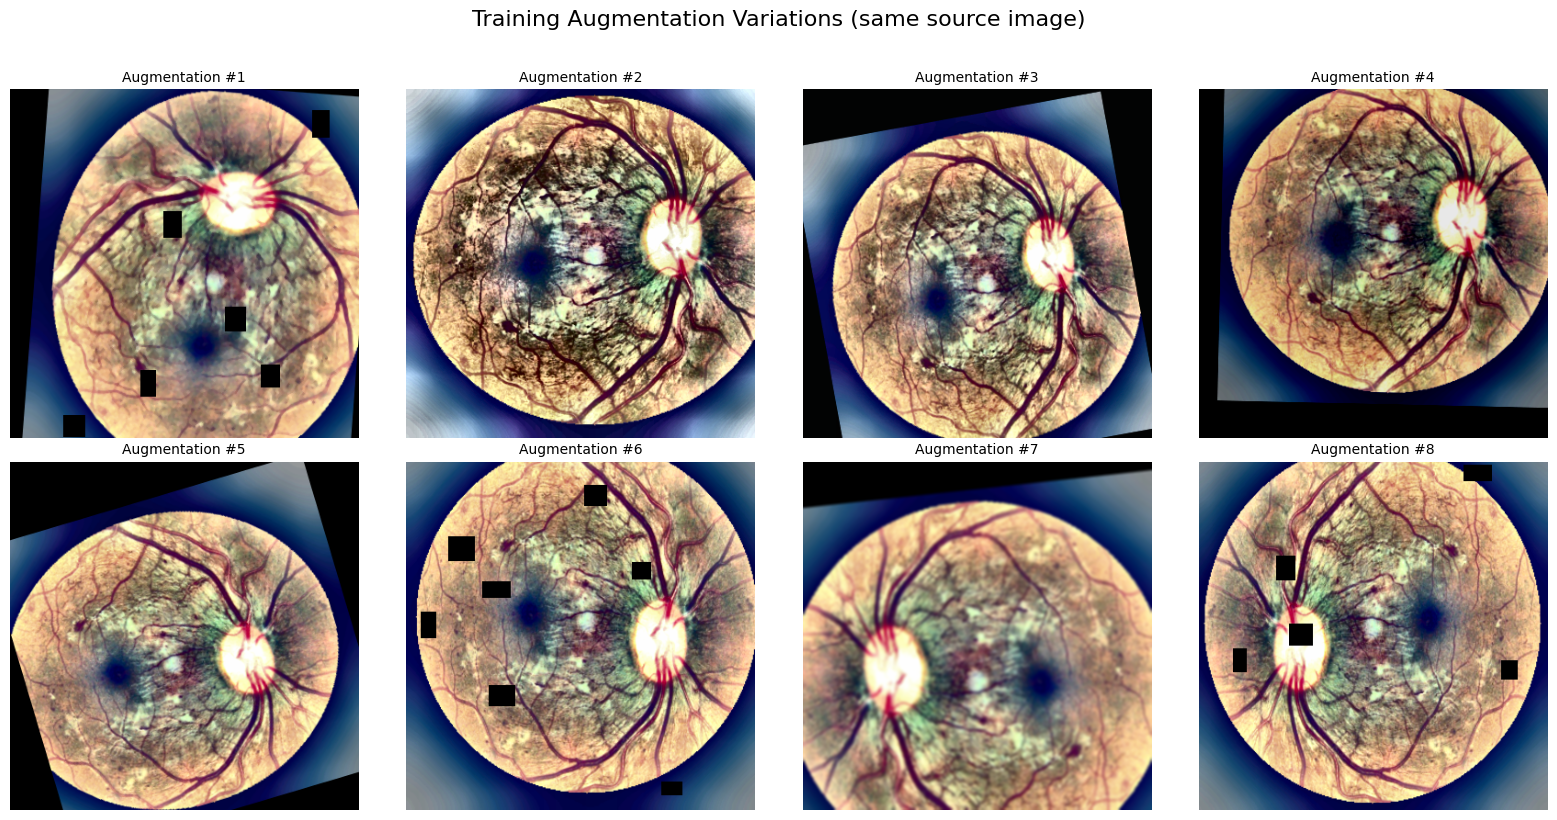

In [13]:
# Show multiple augmented versions of the same preprocessed image
processed = preprocess_image(cv2.cvtColor(cv2.imread(sample_images[3]), cv2.COLOR_BGR2RGB))
train_tfm = get_train_transforms()

n_augments = 8
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Training Augmentation Variations (same source image)', fontsize=16, y=1.02)

for i, ax in enumerate(axes.flat):
    augmented = train_tfm(image=processed)['image']
    # Denormalise for display
    img_np = augmented.permute(1, 2, 0).numpy()
    img_np = img_np * np.array(config.IMG_STD) + np.array(config.IMG_MEAN)
    img_np = np.clip(img_np, 0, 1)
    ax.imshow(img_np)
    ax.set_title(f'Augmentation #{i+1}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, 'augmentation_preview.png'), dpi=150, bbox_inches='tight')
plt.show()

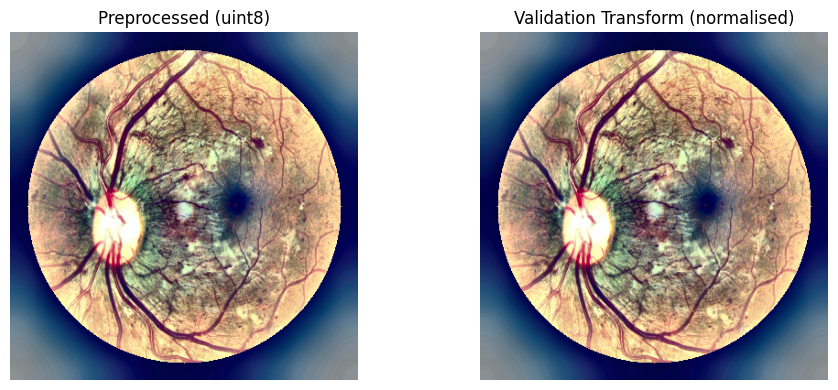

In [14]:
# Show validation transform (deterministic)
val_tfm = get_valid_transforms()
val_result = val_tfm(image=processed)['image']
img_np = val_result.permute(1, 2, 0).numpy()
img_np = img_np * np.array(config.IMG_STD) + np.array(config.IMG_MEAN)
img_np = np.clip(img_np, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(processed)
axes[0].set_title('Preprocessed (uint8)', fontsize=12)
axes[0].axis('off')

axes[1].imshow(img_np)
axes[1].set_title('Validation Transform (normalised)', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()